In [1]:
import anndata
import gc
import geopandas as gpd
import json
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
import scanpy as sc
from scipy import sparse
from shapely.geometry import box
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score

%run functions.ipynb

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


# Histology

### UNI Model

In [ ]:
person = "CRC_P2"
bin_size = "002um"
pred_col = "leiden_0.2" # cluster resolution
patch_size = 224


base_dir = f"../../data/{person}/"
dir_base_output = os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}")
histology_dir = f"../../uni/notebooks/metadata"

adata_filtered_bins = sc.read_h5ad(os.path.join(histology_dir, "filtered_WSI_patch_embeddings.h5ad"))
adata_filtered_bins = adata_filtered_bins[adata_filtered_bins.obs["Slide_ID"] == person]

# Extract needed info
df = adata_filtered_bins.obs[["Slide_ID", "X", "Y", pred_col]].copy()

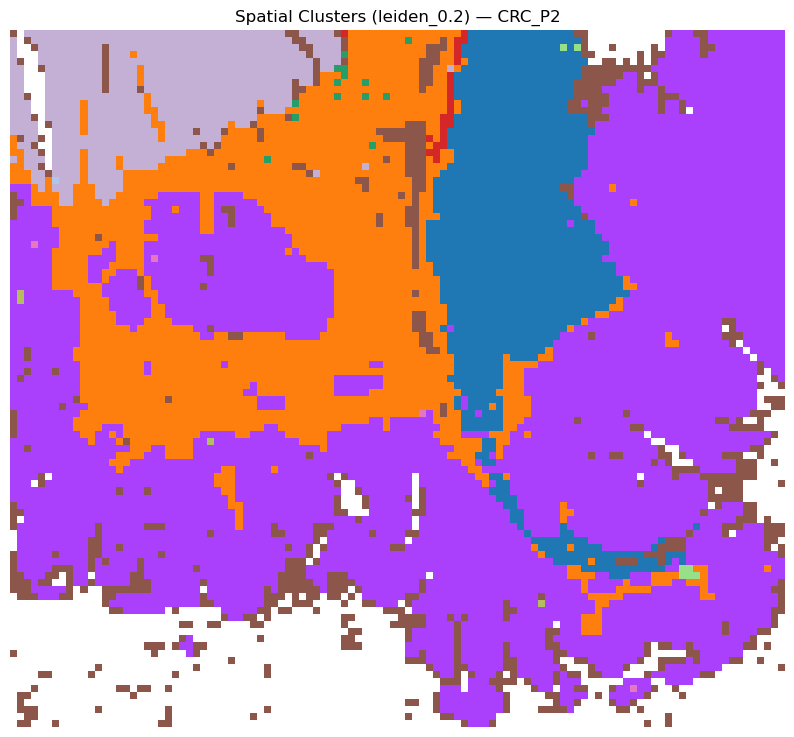

In [ ]:
if f"{pred_col}_colors" in adata_filtered_bins.uns:
    pred_df = sorted(df[pred_col].unique(), key=lambda x: int(x))
    colors = adata_filtered_bins.uns[f"{pred_col}_colors"]
    color_map = {c: colors[i % len(colors)] for i, c in enumerate(pred_df)}
else:
    unique_clusters = df[pred_col].unique()
    cmap = cm.get_cmap("tab20", len(unique_clusters))
    color_map = {c: cmap(i) for i, c in enumerate(unique_clusters)}

# Create figure
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title(f"Spatial Clusters ({pred_col}) — {person}")

# Draw each patch as a colored rectangle
for _, row in df.iterrows():
    x, y = row["X"], row["Y"]
    color = color_map[row[pred_col]]
    rect = patches.Rectangle(
        (x, y), patch_size, patch_size,
        facecolor=color, edgecolor='none'
    )
    ax.add_patch(rect)

# Set coordinate system: top-left = (0,0)
ax.set_xlim(df["X"].min(), df["X"].max() + patch_size)
ax.set_ylim(df["Y"].min() + patch_size, df["Y"].max())
ax.axis("off")

plt.show()

**Comparing with ground truth**  
Since this case deals with patches, but the ground truth is based on bins, we will first assign each bin to a patch.

Then we will evaluate.

In [ ]:
truth_df = pd.read_csv(os.path.join(base_dir, "ground_truth/2um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(os.path.join(dir_base_output, "spatial/tissue_positions.parquet"))
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

scale_path = os.path.join(dir_base_output, "spatial/scalefactors_json.json")

match_dir = os.path.join(base_dir, "ground_truth")
bin_cols = ['Patch_ID', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0']
patch_cols = ['barcode', 'tissuetype', 'in_tissue']
matched_df = assign_bins_to_patches(truth_df, adata_filtered_bins.obs, bin_cols, patch_cols, 'barcode', 
                                    scale_path, match_dir, 224)

In [ ]:
matched_df = pd.read_parquet(os.path.join(base_dir, "ground_truth/bin_patch_clusters.parquet"))

y_true = matched_df['tissuetype']
y_pred = matched_df['leiden_0.2']

results = {
    'Adjusted Rand Index': adjusted_rand_score(y_true, y_pred),
    'Normalized Mutual Info': normalized_mutual_info_score(y_true, y_pred),
    'Homogeneity': homogeneity_score(y_true, y_pred),
    'Completeness': completeness_score(y_true, y_pred),
    'V-Measure': v_measure_score(y_true, y_pred)
}

for k, v in results.items():
    print(f"{k}: {v:.3f}")


Adjusted Rand Index: 0.772
Normalized Mutual Info: 0.687
Homogeneity: 0.728
Completeness: 0.650
V-Measure: 0.687


# Transcriptomics

In [2]:
person = "CRC_P2"
bin_size = "002um"
base_dir = f"../../data/{person}"
dir_base_input = os.path.join(base_dir, "input")
dir_base_output = os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}")

In [3]:
## Helper functions from CustomBinning.ipynb - aken from 10x genomics
# Plotting function for nuclei area distribution
def plot_nuclei_area(gdf,area_cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(15, 4))
    # Plot the histograms
    axs[0].hist(gdf['area'], bins=50, edgecolor='black')
    axs[0].set_title('Nuclei Area')

    axs[1].hist(gdf[gdf['area'] < area_cut_off]['area'], bins=50, edgecolor='black')
    axs[1].set_title('Nuclei Area Filtered:'+str(area_cut_off))

    plt.tight_layout()
    plt.show()

# Total UMI distribution plotting function
def total_umi(adata_, cut_off):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))

    # Box plot
    axs[0].boxplot(adata_.obs["total_counts"], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[0].set_title('Total Counts')

    # Box plot after filtering
    axs[1].boxplot(adata_.obs["total_counts"][adata_.obs["total_counts"] > cut_off], vert=False, widths=0.7, patch_artist=True, boxprops=dict(facecolor='skyblue'))
    axs[1].set_title('Total Counts > ' + str(cut_off))

    # Remove y-axis ticks and labels
    for ax in axs:
        ax.get_yaxis().set_visible(False)

    plt.tight_layout()
    plt.show()

### For bin size 002um: 
We load the filtered feature matrix and assign each bin to a larger 4x4um bin. 
This information is stored in the same dataframe. 
 
We then ...

In [4]:
adata_filtered_bins = sc.read_10x_h5(os.path.join(dir_base_output, "filtered_feature_bc_matrix.h5"))

# Load Spatial Coordinates
tissue_position_file = dir_base_output+'/spatial/tissue_positions.parquet'
df_tissue_positions=pd.read_parquet(tissue_position_file)

#Set the index of the dataframe to the barcodes
df_tissue_positions = df_tissue_positions.set_index('barcode')

# Create an index in the dataframe to check joins
df_tissue_positions['index']=df_tissue_positions.index

# Adding the tissue positions to the meta data
adata_filtered_bins.obs = pd.merge(adata_filtered_bins.obs, df_tissue_positions, left_index=True, right_index=True)

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [5]:
# Params
super_bin_size = 4  # size of large bin in µm (must be even)
small_bin_size = 2  # size of original small bins in µm
scale_factor = super_bin_size // small_bin_size  # number of small bins per large bin side

array_size = adata_filtered_bins.obs["array_col"].max()
print("Total bin count for 2x2um BEFORE filtering: ", array_size**2)
print("Bin count for 2x2um bins AFTER filtering: ", adata_filtered_bins.obs.shape[0])

adata_filtered_bins.obs['large_x'] = adata_filtered_bins.obs['array_col'] // scale_factor
adata_filtered_bins.obs['large_y'] = adata_filtered_bins.obs['array_row'] // scale_factor

# Count small bins per candidate large bin
counts = (
    adata_filtered_bins.obs
    .groupby(['large_x', 'large_y'])
    .size()
    .reset_index(name='n_bins')
)

bin_id = f'{super_bin_size}x{super_bin_size}um_bin_id'

full_bins = counts[counts['n_bins'] == scale_factor**2][['large_x', 'large_y']].copy()
full_bins[bin_id] = range(len(full_bins))
mapping = full_bins.set_index(['large_x', 'large_y'])[bin_id]
adata_filtered_bins.obs[bin_id] = list(zip(adata_filtered_bins.obs['large_x'], adata_filtered_bins.obs['large_y']))

adata_filtered_bins.obs[bin_id] = adata_filtered_bins.obs[bin_id].map(mapping)
adata_filtered_bins.obs.drop(columns=['large_x', 'large_y'], inplace=True)

print(f"Bin count for complete {super_bin_size}x{super_bin_size}um bins: ", 
      adata_filtered_bins.obs[bin_id].unique().shape[0])

# Optionally for storage optimisation
del df_tissue_positions, counts, full_bins, mapping
gc.collect()

Total bin count for 2x2um BEFORE filtering:  11215801
Bin count for 2x2um bins AFTER filtering:  8731400
Bin count for complete 4x4um bins:  2182850


20

**Preprocessing.**  
We now plot the UMI distribution.
The goal is to select a cut off and filter out low-quality bins.

In [ ]:
import numpy as np
from scipy import sparse
import pandas as pd
import anndata

bin_series = adata_filtered_bins.obs[bin_id]       # column with large-bin IDs
group_labels = bin_series.to_numpy()

# -- Get unique large-bin IDs and assignment for each small-bin row
unique_groups, inverse = np.unique(group_labels, return_inverse=True)

N_groups = len(unique_groups)
N_cells = adata_filtered_bins.n_obs

print(f"Number of small bins (rows): {N_cells}")
print(f"Number of large bins (groups): {N_groups}")

# -- Build sparse assignment matrix M (groups × cells)
#    M[i, j] = 1 if cell j belongs to group i, else 0
M = sparse.csr_matrix(
    (np.ones(N_cells, dtype=np.int8), (inverse, np.arange(N_cells))),
    shape=(N_groups, N_cells)
)

# -- Vectorized sum: each row i is the sum of all small bins in group i
print("Summing counts using sparse matrix multiplication...")
summed_counts = M @ adata_filtered_bins.X      # -> shape: (N_groups × N_genes)

# -- Build obs dataframe for resulting AnnData (one row per large bin)
obs_df = pd.DataFrame(
    {bin_id: unique_groups},
    index=unique_groups
)

# -- Construct new AnnData
grouped_filtered_adata = anndata.AnnData(
    X=summed_counts,
    obs=obs_df,
    var=adata_filtered_bins.var
)

# Optional cleanup
del M, group_labels, inverse, summed_counts, obs_df
gc.collect()

Number of small bins (rows): 8731400
Number of large bins (groups): 2182850
Summing counts using sparse matrix multiplication...


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Done! grouped_filtered_adata created.


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


250

In [ ]:
# Group the data by unique bin IDs
# This is the original version by 10x. 
# I used matrix multiplication and Vectorized Grouped Summation for AnnData instead, speeding up the process and saving RAM.
# See cell above.
'''groupby_object = adata_filtered_bins.obs.groupby([bin_id], observed=True)
print("Grouped by bins.")

# Extract the gene expression counts from the AnnData object
counts = adata_filtered_bins.X

var = adata_filtered_bins.var

# Obtain the number of unique bins and the number of genes in the expression data
N_groups = groupby_object.ngroups
N_genes = counts.shape[1]

# Initialize a sparse matrix to store the summed gene counts for each bin
summed_counts = sparse.lil_matrix((N_groups, N_genes))
print("Finished summing up counts.")

del N_groups, N_genes, adata_filtered_bins
gc.collect()

# Lists to store the IDs of polygons and the current row index
polygon_id = []
row = 0

# Iterate over each unique polygon to calculate the sum of gene counts.
for polygons, idx_ in groupby_object.indices.items():
    summed_counts[row] = counts[idx_].sum(0)
    row += 1
    polygon_id.append(polygons)
print("Summed up gene counts.")

# Create and AnnData object from the summed count matrix
summed_counts = summed_counts.tocsr()
obs_df = pd.DataFrame(polygon_id, columns=[bin_id], index=polygon_id)

grouped_filtered_adata = anndata.AnnData(X=summed_counts, obs=obs_df, var=var)

del polygons, summed_counts, obs_df
gc.collect()'''

In [11]:
# Calculate quality control metrics for the original AnnData object
sc.pp.calculate_qc_metrics(grouped_filtered_adata, inplace=True)

Note on the bin size:  
"Each bin contains the gene-wise summation of the UMI counts of a number of 2x2 µm squares. For example, 8x8 µm binned data is the gene-wise sum of the UMI counts from a box that is 4 squares wide by 4 squares tall" (from https://www.10xgenomics.com/analysis-guides/segmentation-visium-hd)

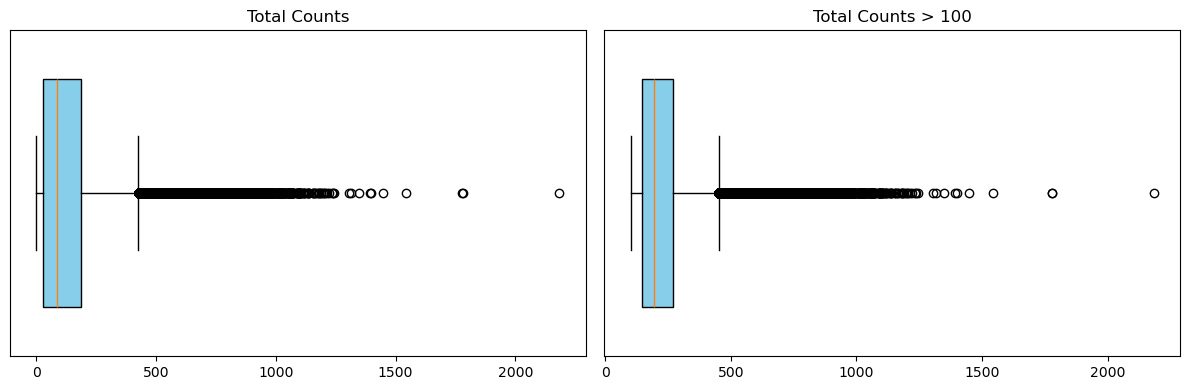

In [16]:
# Plot total UMI distribution (here cutoff = 30. Adapt if necessary)
cutoff=100
total_umi(grouped_filtered_adata, cutoff)

In [17]:
# Create a mask based on the 'total_counts' column for values greater than 100
mask_count = grouped_filtered_adata.obs['total_counts'] > cutoff
count_area_filtered_adata = grouped_filtered_adata[mask_count, :]

# Calculate quality control metrics for the filtered AnnData object
sc.pp.calculate_qc_metrics(count_area_filtered_adata, inplace=True)

#del mask_count, adata_filtered_bins

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[obs_metrics.columns] = obs_metrics
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [ ]:
# Normalize total counts for each cell in the AnnData object
sc.pp.normalize_total(count_area_filtered_adata, inplace=True)

# Logarithmize the values in the AnnData object after normalization
sc.pp.log1p(count_area_filtered_adata)

# Identify highly variable genes in the dataset using the Seurat method
sc.pp.highly_variable_genes(count_area_filtered_adata, flavor="seurat", n_top_genes=2000)

# Perform Principal Component Analysis (PCA) on the AnnData object
sc.pp.pca(count_area_filtered_adata)

# Build a neighborhood graph based on PCA components
sc.pp.neighbors(count_area_filtered_adata)

# Perform Leiden clustering on the neighborhood graph and store the results in 'clusters' column

# Adjust the resolution parameter as needed for different samples
sc.tl.leiden(count_area_filtered_adata, resolution=0.2, key_added="clusters")

count_area_filtered_adata.write (f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning/{super_bin_size}x{super_bin_size}um_count_area_filtered_adata.h5ad")

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-11-17 16:29:16.581384: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-17 16:29:16.680148: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/tmp/ipykernel_87104/2219970675.py:19: FutureWarning: In the future, the default backen

In [21]:
count_area_filtered_adata.obs["clusters"].unique

<bound method Series.unique of 90          0
91         49
118        31
145         0
146         0
           ..
2182841     1
2182842     0
2182843     3
2182844    24
2182845     4
Name: clusters, Length: 1014599, dtype: category
Categories (196, object): ['0', '1', '2', '3', ..., '192', '193', '194', '195']>

In [ ]:
plot_bin_clusters(count_area_filtered_adata.obs, 'pxl_col_in_fullres', 'pxl_row_in_fullres', 'clusters')

### For bin size 008um and 016um
Clustering results are already provided by 10x Genomics. 
Hence, we just use the same plotting function, but for larger bins.

In [14]:
cluster_type = "kmeans_6_clusters" # in spaceranger output: either kmeans or graphclust. Also name of directory
pred_col = "Cluster" # column with predicted cluster info in csv 
pred_cluster_path = os.path.join(dir_base_output, f"analysis/clustering/gene_expression_{cluster_type}/clusters.csv")
pred_df = pd.read_csv(pred_cluster_path, delimiter=',')
pred_df.rename(columns={'Barcode': 'barcode'}, inplace=True)

# Merge cluster annotation with the bin positions
tissue_positions = pd.read_parquet(os.path.join(dir_base_output, "spatial/tissue_positions.parquet"))
pred_df = pd.merge(pred_df, tissue_positions, on='barcode', how='left')
del tissue_positions

truth_col = "tissuetype"
truth_df = pd.read_csv(os.path.join(base_dir, "ground_truth/8um_squares_annotation.csv"), 
                                        delimiter='\t', header=None, names=['barcode', 'tissuetype'])
tissue_positions = pd.read_parquet(os.path.join(base_dir, f"output/binned_outputs/square_{bin_size}/spatial/tissue_positions.parquet"))
truth_df = pd.merge(truth_df, tissue_positions, on='barcode', how='left')

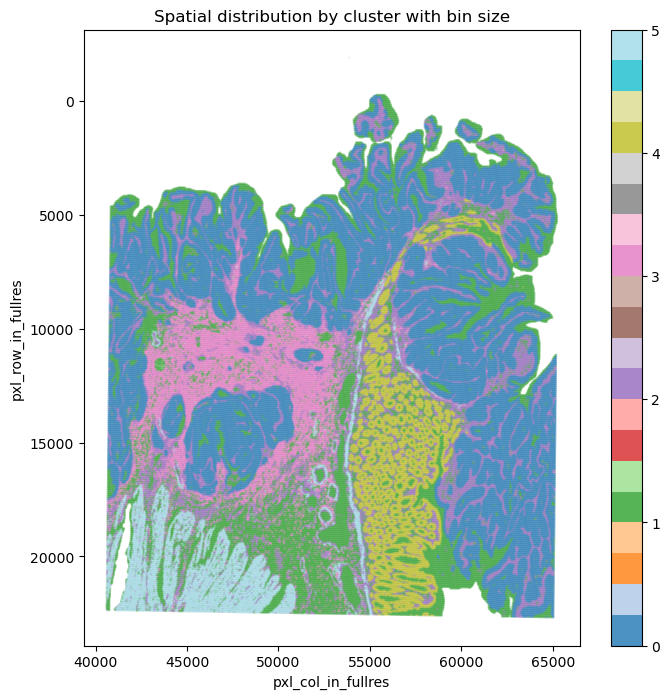

In [16]:
# Plotting the Clusters given in the spaceranger analysis 
plot_bin_clusters(pred_df, 'pxl_col_in_fullres', 'pxl_row_in_fullres', pred_col)

In [ ]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')

get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.182
Normalized Mutual Info: 0.361
Homogeneity: 0.548
Completeness: 0.269
V-Measure: 0.361


In [15]:
merged_df = pd.merge(truth_df, pred_df, on='barcode', how='left')
get_eval_scores(merged_df, pred_col, truth_col)

Found 63 NaN values in 'Cluster' and 0 in 'tissuetype' out of 545913 rows. Dropping rows ...
Adjusted Rand Index: 0.401
Normalized Mutual Info: 0.414
Homogeneity: 0.487
Completeness: 0.360
V-Measure: 0.414


### Clustering for nuclei
After nuclei segmentation, we have bins assigned to nuclei. 
Similar to the results abie, we will now evaluate the clustering results from the preprocessed nuclei/bins.

In [10]:
dir_cell_seg = f"../../Cell_Segmentation/output/{person}/{bin_size}/custom_binning"
nuclei_info = sc.read_h5ad(os.path.join(dir_cell_seg, "count_area_filtered_adata.h5ad"))
bin_info = sc.read_h5ad(os.path.join(dir_cell_seg, "filtered_custom_bins.h5ad"))
ground_truth = pd.read_csv(os.path.join(base_dir, f"ground_truth/2um_squares_annotation.csv"), delimiter='\t', header=None, names=['barcode', 'ground_truth'])

nuclei_obs = nuclei_info.obs.copy()
bin_obs = bin_info.obs.copy()

# Join bins with nucleus info 
merged_obs = bin_obs.join(nuclei_obs[["id", "clusters"]].set_index("id"), on="id", how="inner")
# Join with ground truth
merged_obs = merged_obs.join(ground_truth.set_index("barcode"), how="inner")

merged_obs = merged_obs.drop(columns=["in_tissue", "array_row", "array_col", "index_x", "index_y", "is_within_polygon", 
                                      "is_not_in_an_polygon_overlap", "Slide_ID"]) # readability
merged_obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,pxl_row_in_fullres,pxl_col_in_fullres,id,clusters,ground_truth
s_002um_02804_02579-1,2151.486689,59672.567145,ID_17953,1,Neoplasm
s_002um_02344_00939-1,5354.080943,47656.445293,ID_107451,0,Neoplasm
s_002um_01281_00027-1,13028.244901,40898.862634,ID_346489,11,Neoplasm
s_002um_01585_00778-1,10880.388619,46409.684991,ID_348900,0,Connective Tissue
s_002um_02437_00596-1,4642.442923,45161.359620,ID_94002,14,Neoplasm
...,...,...,...,...,...
s_002um_01161_02946-1,14183.699316,62198.437800,ID_384268,0,Neoplasm
s_002um_02139_01546-1,6908.652332,52068.422539,ID_110662,1,Neoplasm
s_002um_00296_02357-1,20444.066759,57816.672851,ID_683990,4,Non-neoplastic Epithelium
s_002um_02335_01731-1,5495.195497,53437.436588,ID_112376,3,Neoplasm


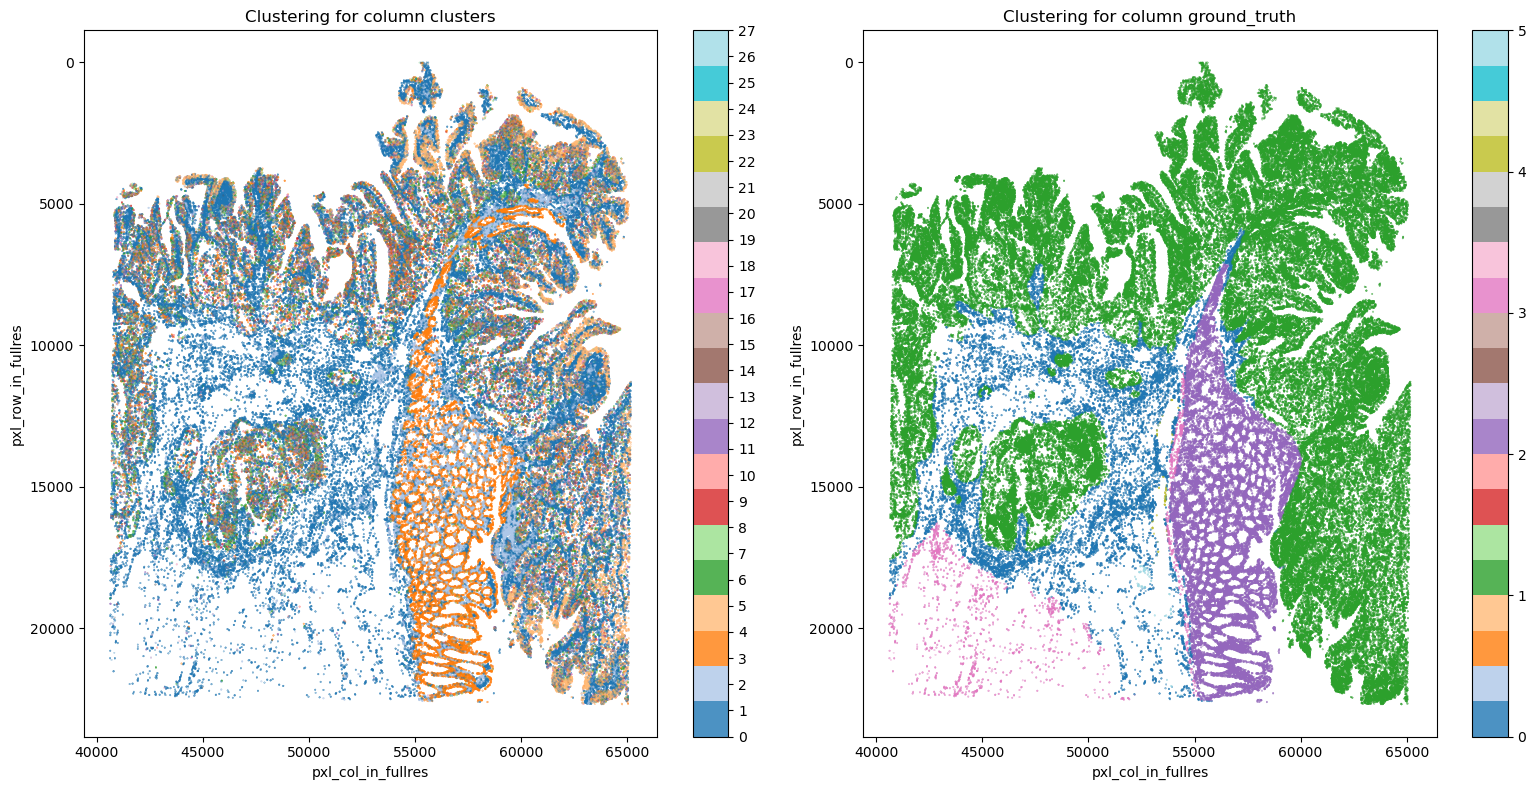

In [12]:
plot_bin_clusters_side_by_side(merged_obs, 'pxl_col_in_fullres', 'pxl_row_in_fullres', "clusters", "ground_truth")

In [13]:
get_eval_scores(merged_obs, "clusters", "ground_truth")

Adjusted Rand Index: -0.004
Normalized Mutual Info: 0.169
Homogeneity: 0.344
Completeness: 0.112
V-Measure: 0.169


In [8]:
import pandas as pd
import os
df = pd.read_csv(os.path.join(dir_cell_seg, 'segmented_nuclei_ground_truth_i_think/output/coordinates.tsv'), sep='\t')
df

,Unnamed: 0,x,y
0,0,54192.421560,2324.201920
1,1,48290.763479,4619.085810
2,2,47994.656665,6731.686582
3,3,47531.629731,4630.575467
4,4,48048.706305,4118.533680
...,...,...,...
305585,305585,47059.198576,7353.833198
305586,305586,49956.573744,4900.786454
305587,305587,47403.295929,4482.034077
305588,305588,47494.804288,7164.797806


In [9]:
df = pd.read_csv(os.path.join(dir_cell_seg, 'segmented_nuclei_ground_truth_i_think/output/features.tsv'), sep='\t')
df

,Unnamed: 0,gene_ids,feature_types,genome,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,selected
0,SAMD11,ENSG00000187634,Gene Expression,GRCh38,299,0.000982,0.000981,99.902156,300.0,5.707110,True
1,NOC2L,ENSG00000188976,Gene Expression,GRCh38,2103,0.006954,0.006930,99.311823,2125.0,7.661998,True
2,KLHL17,ENSG00000187961,Gene Expression,GRCh38,600,0.001973,0.001971,99.803658,603.0,6.403574,True
3,PLEKHN1,ENSG00000187583,Gene Expression,GRCh38,1283,0.004241,0.004232,99.580156,1296.0,7.167809,True
4,PERM1,ENSG00000187642,Gene Expression,GRCh38,25,0.000082,0.000082,99.991819,25.0,3.258097,True
...,...,...,...,...,...,...,...,...,...,...,...
18080,MT-ND4L,ENSG00000212907,Gene Expression,GRCh38,105593,0.698164,0.529548,65.446186,213352.0,12.270703,True
18081,MT-ND4,ENSG00000198886,Gene Expression,GRCh38,197425,3.233489,1.443027,35.395465,988122.0,13.803562,True
18082,MT-ND5,ENSG00000198786,Gene Expression,GRCh38,40729,0.160071,0.148481,86.672012,48916.0,10.797880,True
18083,MT-ND6,ENSG00000198695,Gene Expression,GRCh38,48416,0.195409,0.178488,84.156550,59715.0,10.997355,True


In [12]:
df = pd.read_csv(os.path.join(dir_cell_seg, 'segmented_nuclei_ground_truth_i_think/output/labels.tsv'), sep='\t')
df["annotation"].unique()

array(['Neoplasm', 'Connective Tissue', 'Non-neoplastic Epithelium',
       'Veins', 'Smooth Muscle', 'Vessel'], dtype=object)

In [11]:
df = pd.read_csv(os.path.join(dir_cell_seg, 'segmented_nuclei_ground_truth_i_think/output/observations.tsv'), sep='\t')
df

,Unnamed: 0,id,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,filtered,area,region,annotation,selected
0,0,9186,16,2.833213,18.0,2.944439,100.000000,100.000000,100.000000,100.00000,yes,573.132047,nuclei,Neoplasm,False
1,1,9204,189,5.247024,200.0,5.303305,30.500000,55.500000,100.000000,100.00000,no,276.452746,nuclei,Neoplasm,True
2,2,9224,284,5.652489,395.0,5.981414,40.759494,53.417722,78.734177,100.00000,no,599.447374,nuclei,Neoplasm,True
3,3,9267,152,5.030438,169.0,5.135798,39.644970,69.230769,100.000000,100.00000,no,336.177545,nuclei,Neoplasm,True
4,4,9274,363,5.897154,441.0,6.091310,29.024943,40.362812,63.038549,100.00000,no,431.643913,nuclei,Neoplasm,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
305585,305585,838149,316,5.758902,343.0,5.840642,22.448980,37.026239,66.180758,100.00000,no,269.134092,nuclei,Neoplasm,True
305586,305586,838164,58,4.077537,64.0,4.174387,87.500000,100.000000,100.000000,100.00000,no,588.863140,nuclei,Neoplasm,True
305587,305587,838169,193,5.267858,215.0,5.375278,33.488372,56.744186,100.000000,100.00000,no,372.033227,nuclei,Neoplasm,True
305588,305588,838172,208,5.342334,213.0,5.365976,25.821596,49.295775,96.244131,100.00000,no,299.921540,nuclei,Neoplasm,True
